# CENG313 Assignment 1: EDA & Baseline
**Group 31** · Competition: [MAP – Charting Student Math Misunderstandings](https://www.kaggle.com/competitions/map-charting-student-math-misunderstandings)

## 1. Problem definition

On the Eedi platform students answer a multiple-choice maths question and then explain their choice in their own words.
Teachers want to know **whether the explanation shows a misconception and which one**.

- **Input:** the question (`QuestionId`, `QuestionText`), the chosen answer (`MC_Answer`) and the free-text `StudentExplanation`.
- **Target:** one label `Category:Misconception`, for example `False_Misconception:Incomplete` or `True_Correct:NA`.
  - `Category` = *is the chosen answer right?* (`True` / `False`) + *what does the explanation show?* (`Correct` / `Misconception` / `Neither`).
  - `Misconception` = the name of the misconception, or `NA` when the category has none.
- **Task type:** multi-class text classification (NLP).
- **Metric:** **MAP@3**. For each row we submit up to 3 labels in order. A correct label at rank 1, 2 or 3 earns 1, 1/2 or 1/3 points; otherwise 0. The score is the mean over all rows.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

from src.data import add_target, clean_text, find_correct_answers, load_data, preprocess
from src.models import allowed_mask, majority_top3, top3_from_proba, train_baseline
from src.utils import bar_counts, map_at_3, save_submission

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## 2. Data overview

We load the data with `keep_default_na=False`: in this dataset the string `"NA"` in `Misconception` is a **real label** ("no misconception"), not a missing value. With the pandas default it would silently turn into `NaN`.

In [2]:
train, test = load_data("data")
train = add_target(train)
print("train:", train.shape, " test:", test.shape)
train.head()

train: (36696, 8)  test: (3, 5)


,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception,target
0,0,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Image: A triangle split into 9 equ...,\( \frac{1}{3} \),0ne third is equal to tree nineth,True_Correct,NA,True_Correct:NA
1,1,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Image: A triangle split into 9 equ...,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third is not shaded.,True_Correct,NA,True_Correct:NA
2,2,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Image: A triangle split into 9 equ...,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to understand.",True_Neither,NA,True_Neither:NA
3,3,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Image: A triangle split into 9 equ...,\( \frac{1}{3} \),1 goes into everything and 3 goes into nine,True_Neither,NA,True_Neither:NA
4,4,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Image: A triangle split into 9 equ...,\( \frac{1}{3} \),1 out of every 3 isn't coloured,True_Correct,NA,True_Correct:NA


In [3]:
train.dtypes

row_id                int64
QuestionId            int64
QuestionText            str
MC_Answer               str
StudentExplanation      str
Category                str
Misconception           str
target                  str
dtype: object

In [4]:
train.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
row_id,36696.0,NaN,NaN,NaN,18347.5,10593.367076,0.0,9173.75,18347.5,27521.25,36695.0
QuestionId,36696.0,NaN,NaN,NaN,46356.825104,25617.723392,31772.0,31777.0,32833.0,33474.0,109465.0
QuestionText,36696,15,What fraction of the shape is not shaded? Give your answer in its simplest form. [Image: A triangle split into 9 equ...,4857,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MC_Answer,36696,49,\( \frac{1}{3} \),2599,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StudentExplanation,36696,35726,i think this because 24 divided by 2 is 12,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,36696,6,True_Correct,14802,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Misconception,36696,36,NA,26836,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target,36696,65,True_Correct:NA,14802,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Missing values per column:")
print(train.isna().sum())

Missing values per column:
row_id                0
QuestionId            0
QuestionText          0
MC_Answer             0
StudentExplanation    0
Category              0
Misconception         0
target                0
dtype: int64


In [6]:
key = ["QuestionId", "MC_Answer", "StudentExplanation"]
dup_mask = train.duplicated(subset=key, keep=False)
dups = train[dup_mask]
conflicts = dups.groupby(key)["target"].nunique()

print("Fully identical rows (all columns except row_id):", train.drop(columns="row_id").duplicated().sum())
print("Rows that repeat an earlier (question, answer, explanation):", train.duplicated(subset=key).sum())
print("Repeated explanations that got DIFFERENT labels:", (conflicts > 1).sum())
dups[dups.set_index(key).index.isin(conflicts[conflicts > 1].index)].sort_values(key).head(6)[key[1:] + ["target"]]

Fully identical rows (all columns except row_id): 736
Rows that repeat an earlier (question, answer, explanation): 797
Repeated explanations that got DIFFERENT labels: 61


,MC_Answer,StudentExplanation,target
38,\( \frac{1}{3} \),"1/3 of the 9 triangles are shaded, so 3/9=1/3.",True_Correct:NA
39,\( \frac{1}{3} \),"1/3 of the 9 triangles are shaded, so 3/9=1/3.",True_Neither:NA
79,\( \frac{1}{3} \),3 of the 9 triangles are shaded simplest form is 1/3,True_Correct:NA
80,\( \frac{1}{3} \),3 of the 9 triangles are shaded simplest form is 1/3,True_Neither:NA
119,\( \frac{1}{3} \),3 out of 9 triangles are not shaded.,True_Correct:NA
120,\( \frac{1}{3} \),3 out of 9 triangles are not shaded.,True_Misconception:Incomplete


- 36,696 training rows. The file has 7 columns (8 after we add `target`), all text except `row_id` and `QuestionId`.
- The local `test.csv` has only **3 rows**. The real test set (about 16,000 rows) is hidden and only used when Kaggle re-runs our notebook, so we cannot inspect it. All model selection has to be done on a validation split of `train.csv`.
- There are **no missing values** once `"NA"` is read correctly, so no imputation is needed.
- There are only **15 different questions**, which means every question has thousands of student answers.
- 797 rows repeat an earlier (question, answer, explanation). In 494 of the 580 repeated groups the copies sit on consecutive `row_id`s, so they look like the same answer stored twice. 61 groups carry **different labels** for identical text (rows 38 and 39 above: `True_Correct` vs `True_Neither`). No model can get both copies right, so the best reachable score is below 1.0.

## 3. Exploratory data analysis

### 3.1 Category (part 1 of the target)

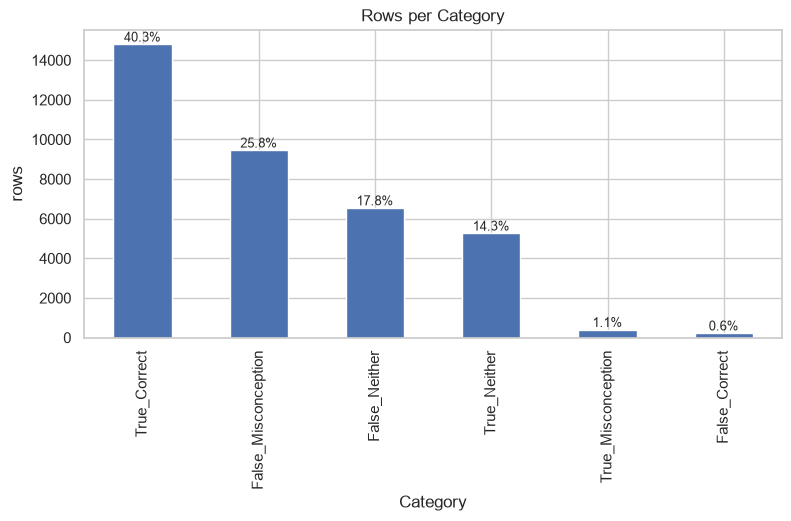

In [7]:
ax = bar_counts(train["Category"], "Rows per Category")
for p in ax.patches:
    ax.annotate(f"{p.get_height() / len(train):.1%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.show()

`True_Correct` alone is 40 % of the data, while `True_Misconception` (right answer, wrong reasoning) and `False_Correct` (wrong answer, sensible reasoning) are about 1 % or less each.
A model that never predicts the two rare classes loses less than 2 % of rows, so it has little reason to learn them. MAP@3 softens this a bit: a rare label still earns 1/2 or 1/3 at rank 2 or 3.
When we split the data we stratify on `Category`, so the validation set keeps these proportions.

### 3.2 Misconception (part 2 of the target)

73.1% of rows have Misconception = NA
Number of distinct misconceptions: 35


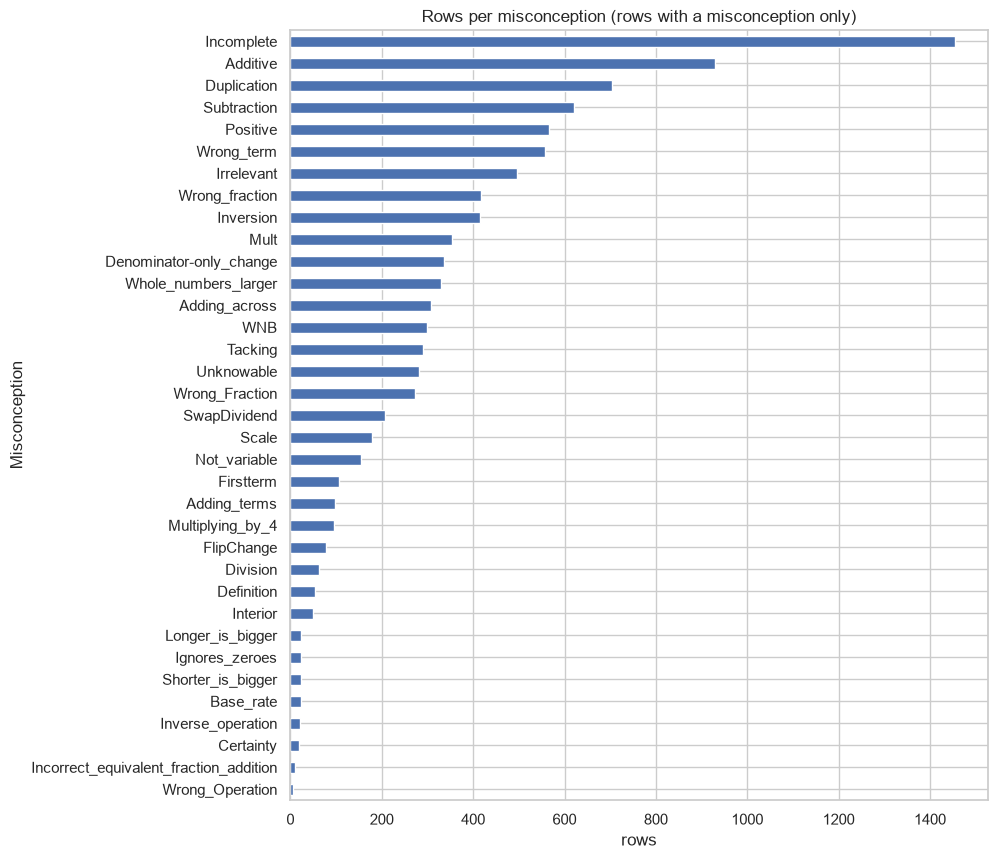

In [8]:
mis = train.loc[train["Misconception"] != "NA", "Misconception"]
print(f"{(train['Misconception'] == 'NA').mean():.1%} of rows have Misconception = NA")
print("Number of distinct misconceptions:", mis.nunique())
fig, ax = plt.subplots(figsize=(9, 10))
bar_counts(mis, "Rows per misconception (rows with a misconception only)", ax=ax, horizontal=True)
plt.show()

73 % of rows have no misconception (`NA`). The other 27 % are spread over 35 names with a long tail: `Incomplete`, `Additive` and `Duplication` have between 704 and 1,454 rows each, while `Wrong_Operation` has 6 and `Incorrect_equivalent_fraction_addition` has 9.
With under 25 examples, a model sees too few explanations to learn these names. Section 5 shows the cost per category.

### 3.3 The combined target `Category:Misconception`

In [9]:
target_counts = train["target"].value_counts()
print("Distinct target labels:", len(target_counts))
print("Labels with fewer than 10 rows:", (target_counts < 10).sum())
print("Labels with exactly 1 row:", (target_counts == 1).sum())
target_counts.head(10)

Distinct target labels: 65
Labels with fewer than 10 rows: 24
Labels with exactly 1 row: 5


target
True_Correct:NA                       14802
False_Neither:NA                       6542
True_Neither:NA                        5265
False_Misconception:Incomplete         1446
False_Misconception:Additive            891
False_Misconception:Duplication         698
False_Misconception:Subtraction         618
False_Misconception:Positive            564
False_Misconception:Wrong_term          550
False_Misconception:Wrong_fraction      412
Name: count, dtype: int64

Together the two parts form **65 classes**. Some of them appear only once, so a split stratified on the full target is impossible (scikit-learn needs at least 2 rows per class). That is another reason to stratify on `Category` instead.

### 3.4 Labels per question

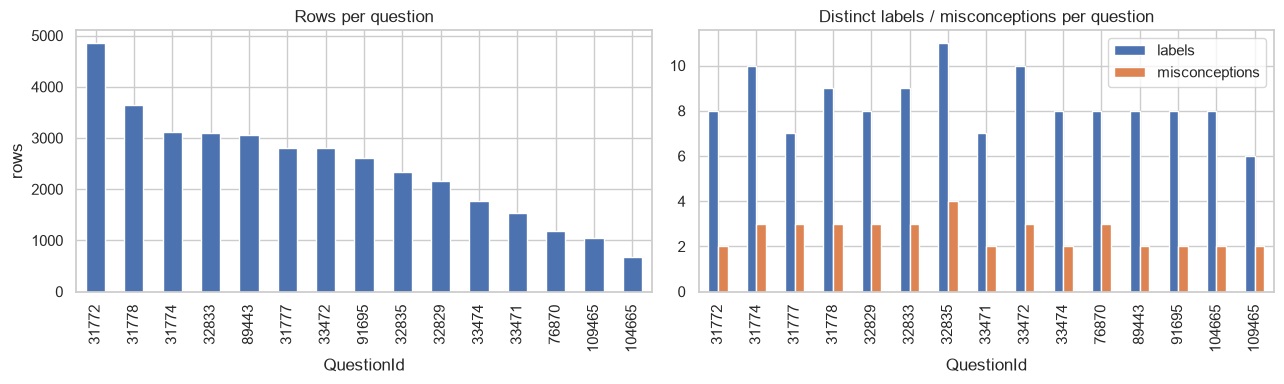

,labels,misconceptions
min,6.000000,2.0
mean,8.333333,2.6
max,11.000000,4.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bar_counts(train["QuestionId"].astype(str), "Rows per question", ax=axes[0])
per_q = train.groupby("QuestionId").agg(labels=("target", "nunique"),
                                        misconceptions=("Misconception", lambda s: s[s != "NA"].nunique()))
per_q.plot.bar(ax=axes[1], color=["#4C72B0", "#DD8452"])
axes[1].set_title("Distinct labels / misconceptions per question")
plt.tight_layout()
plt.show()
per_q.describe().loc[["min", "mean", "max"]]

The questions have between 673 and 4,857 rows each, so the model sees far more examples for some questions than for others. Each question has only 6 to 11 distinct labels and 2 to 4 distinct misconceptions. The heatmap below shows which ones.

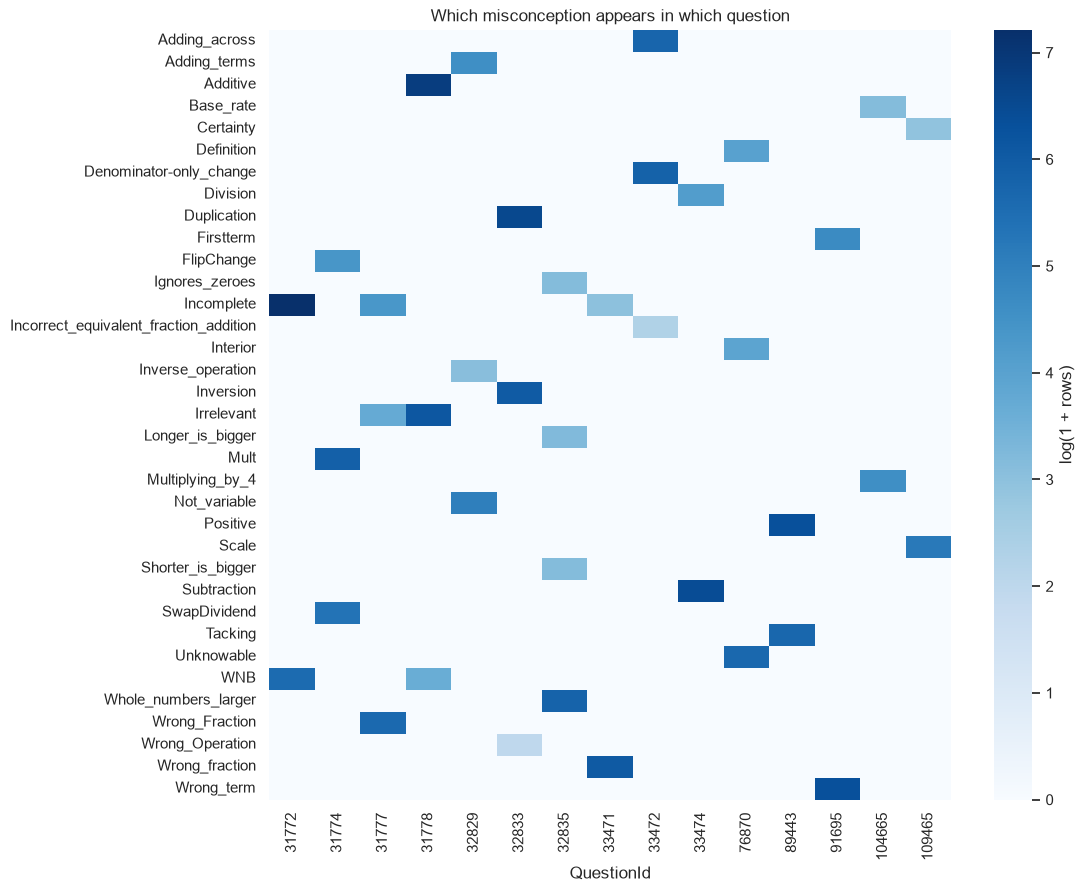

In [11]:
crosstab = pd.crosstab(mis, train.loc[mis.index, "QuestionId"])
plt.figure(figsize=(11, 10))
sns.heatmap(np.log1p(crosstab), cmap="Blues", cbar_kws={"label": "log(1 + rows)"})
plt.title("Which misconception appears in which question")
plt.xlabel("QuestionId")
plt.ylabel("")
plt.show()

**Every misconception belongs to one or a few questions**, and each question has only 2–4 different misconceptions (`Incomplete` appears in 3 questions, `Irrelevant` and `WNB` in 2, every other name in 1).
The heatmap also shows a naming problem: `Wrong_Fraction` (question 31777) and `Wrong_fraction` (question 33471) differ only in capitalisation. Because they belong to different questions we keep them as two labels, exactly as Kaggle scores them, and we must not lowercase the labels.
So once we know the `QuestionId`, out of 65 labels only 6–11 are realistic. We use this later: the model may only rank labels that were seen for that question in the training data.
The next cell checks that the local `test.csv` only uses questions from train. The hidden test set cannot be checked. A new question would have no known right answer, so `is_correct` would be 0 and the text would say `correct no` even for a right answer. The label mask itself would block every label for that row, which leaves the plain model ranking unchanged.

In [12]:
print("All test questions appear in train:", test["QuestionId"].isin(train["QuestionId"]).all())

All test questions appear in train: True


### 3.5 Chosen answer vs. the True/False part of Category

In [13]:
train["answer_is_right"] = train["Category"].str.split("_").str[0]
purity = (train.groupby(["QuestionId", "MC_Answer"])["answer_is_right"]
          .agg(lambda s: s.value_counts(normalize=True).iloc[0]))
print("(question, answer) pairs:", len(purity))
print("pairs where every row has the same True/False:", (purity == 1).sum())

correct_answers = find_correct_answers(train)
tmp = preprocess(train, correct_answers)
agreement = ((tmp["is_correct"] == 1) == (tmp["answer_is_right"] == "True")).mean()
print(f"is_correct feature matches True/False label on {agreement:.2%} of rows")

pd.crosstab(tmp["is_correct"].map({1: "picked right answer", 0: "picked wrong answer"}), tmp["Category"])

(question, answer) pairs: 60
pairs where every row has the same True/False: 58
is_correct feature matches True/False label on 99.95% of rows


Category,False_Correct,False_Misconception,False_Neither,True_Correct,True_Misconception,True_Neither
is_correct,,,,,,
picked right answer,0,0,6,14796,402,5260
picked wrong answer,227,9457,6536,6,1,5


Each question has 4 answer options, so there are 15 × 4 = 60 (question, answer) pairs. In 58 of them all rows carry the same `True`/`False`; in the other two at least 92 % do. `True`/`False` only records whether the chosen option is right, so this is expected.
We can therefore compute the right answer for each question from the training data (the answer that `True_*` rows chose). The resulting feature `is_correct` matches the label on 99.95 % of rows.
Half of the target is thus known **without reading the explanation**. The text only has to separate `Correct` / `Misconception` / `Neither` and name the misconception.
The crosstab also shows that of 16,220 students who picked a wrong answer, only 227 (1.4 %) gave a correct explanation.

### 3.6 Explanation length and outliers

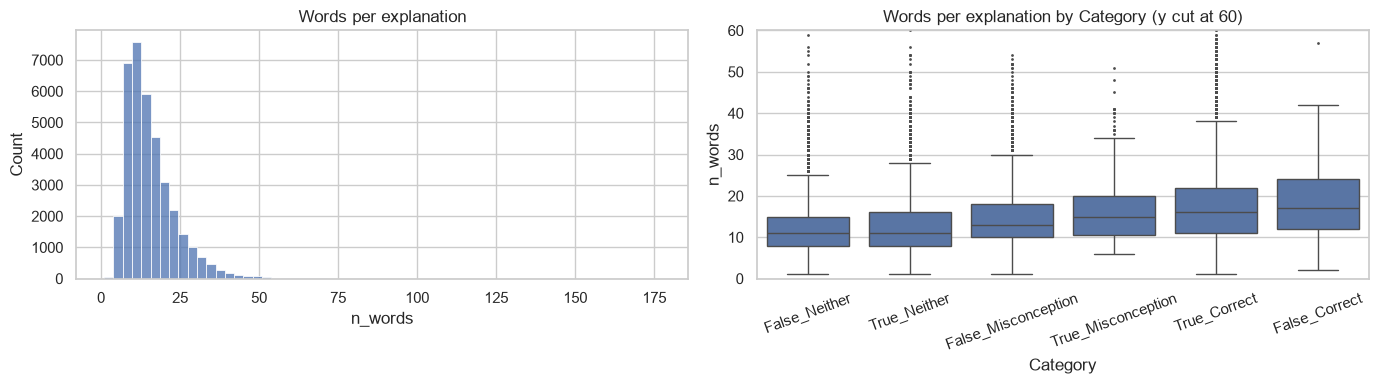

count    36696.000000
mean        15.357832
std          8.121211
min          1.000000
25%         10.000000
50%         13.000000
75%         19.000000
max        177.000000
Name: n_words, dtype: float64

In [14]:
train["n_words"] = train["StudentExplanation"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train["n_words"], bins=60, ax=axes[0])
axes[0].set_title("Words per explanation")
order = train.groupby("Category")["n_words"].median().sort_values().index
sns.boxplot(data=train, x="Category", y="n_words", order=order, ax=axes[1], fliersize=1)
axes[1].set_ylim(0, 60)
axes[1].set_title("Words per explanation by Category (y cut at 60)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
train["n_words"].describe()

In [15]:
train.nlargest(3, "n_words")[["n_words", "StudentExplanation", "target"]]

,n_words,StudentExplanation,target
30422,177,a - subtract b if c is positive elif it is negative f = 0 r = 1 k = 2 l = 3 x 3 = 6 m y = 4 s i = 5 n = 30 j = 10 d ...,True_Neither:NA
17022,112,"In order to do this, you will have to turn the 5 into a 1 and then times 2 3s and 5 1s together making 10 3d. Then, ...",True_Correct:NA
18086,99,"to work out this question, you only really need to do one sum. with a bit of mental working out. the one sum you nee...",True_Correct:NA


Explanations are short: median 13 words, 75 % have 19 words or fewer. The distribution is right-skewed with a few outliers above 100 words.
The longest one (177 words) is nonsense, and the annotators already labelled it `True_Neither`. The next ones are real explanations written at length. Both kinds are valid examples of their label, so we **keep** them. TF-IDF normalises every row, so long texts do not dominate.
Length differs by category: `Neither` explanations are the shortest (median 11 words, often "i guessed" or "because it is"), while `Correct` explanations are longer.
The boxes overlap heavily, so length alone cannot separate the categories.

### 3.7 Most frequent words per category

In [16]:
def top_words(texts, n=12):
    vec = CountVectorizer(stop_words="english", min_df=5)
    counts = vec.fit_transform(texts.map(clean_text)).sum(axis=0).A1
    return pd.Series(counts, index=vec.get_feature_names_out()).nlargest(n).index.tolist()

pd.DataFrame({cat: top_words(train.loc[train["Category"] == cat, "StudentExplanation"])
              for cat in ["True_Correct", "False_Misconception", "False_Neither"]})

,True_Correct,False_Misconception,False_Neither
0,24,15,think
1,15,think,answer
2,times,times,times
3,12,10,number
4,think,shaded,shaded
5,10,answer,add
6,answer,add,15
7,divided,24,negative
8,number,triangles,24
9,120,number,13


Many top words (`3`, `9`, `fraction`, `shaded` …) come from the question topics and appear in every category, so the text has to be read **together with the question and answer**.
Single words separate the categories poorly: `think`, `times` and `answer` are near the top for all three. Only a few words lean to one side (`just` and `negative` for `False_Neither`, `away` for `False_Misconception`). So keyword rules would not work. We give the model word pairs (2-grams) and let it weigh them.
The first rows of the data also show heavy spelling mistakes ("0ne third is equal to tree nineth"). This is why we add **character n-grams** to the features: they still match when a word is misspelled.

## 4. Preprocessing

| Step | What we do | Why |
|---|---|---|
| Missing values | Read `"NA"` as a label, no imputation | There are no real missing values (Section 2) |
| Duplicates | Drop rows that repeat question, answer, explanation **and** label. Keep repeats with different labels | Exact copies add nothing and could end up in both train and validation, which would inflate the score. Conflicting copies are real label noise, so we leave them |
| Target | `Category + ":" + Misconception` → 65 classes | This is the format Kaggle scores |
| `is_correct` | 1 if `MC_Answer` equals the right answer found in train | Gives the model the True/False half of the label (Section 3.5) |
| Text cleaning | Lowercase, remove the LaTeX delimiters `\(` `\)`, squeeze spaces | Answers are stored as LaTeX (`\( \frac{1}{3} \)`). The delimiters carry no meaning |
| Text input | `"answer <MC_Answer> correct <yes/no> explanation <text>"` | One string that TF-IDF can read, including the answer the student is defending |
| Encoding | TF-IDF on word 1–2-grams + character 2–5-grams | Turns text into numbers. Character n-grams cope with spelling mistakes (Section 3.7) |
| Scaling | None extra | TF-IDF vectors are already L2-normalised |
| `QuestionText` | Not used as a feature | There are only 15 questions, so the text would act as an ID. We use the question as a constraint instead (Section 3.4) |

In [17]:
before = len(train)
train = train.drop_duplicates(subset=key + ["target"]).reset_index(drop=True)
print(f"Dropped {before - len(train)} exact duplicate rows → {len(train)} rows left")

correct_answers = find_correct_answers(train)
train = preprocess(train, correct_answers)
train[["MC_Answer", "StudentExplanation", "is_correct", "text", "target"]].head(3)

Dropped 736 exact duplicate rows → 35960 rows left


,MC_Answer,StudentExplanation,is_correct,text,target
0,\( \frac{1}{3} \),0ne third is equal to tree nineth,1,answer \frac{1}{3} correct yes explanation 0ne third is equal to tree nineth,True_Correct:NA
1,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third is not shaded.,1,answer \frac{1}{3} correct yes explanation 1 / 3 because 6 over 9 is 2 thirds and 1 third is not shaded.,True_Correct:NA
2,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to understand.",1,"answer \frac{1}{3} correct yes explanation 1 3rd is half of 3 6th, so it is simplee to understand.",True_Neither:NA


**Train/validation split.** We hold out 20 % of the rows (`random_state=42`), stratified on `Category`. A split stratified on the full 65-class target fails because some labels have only one row.
The right answers (`is_correct`) and the labels allowed per question are computed **from the training part only**, so the validation set stays unseen.

In [18]:
tr, val = train_test_split(train, test_size=0.2, random_state=42, stratify=train["Category"])
correct_tr = find_correct_answers(tr)
tr, val = preprocess(tr, correct_tr), preprocess(val, correct_tr)
labels_per_question = tr.groupby("QuestionId")["target"].agg(set).to_dict()
print("train:", tr.shape, " validation:", val.shape)
print("validation labels never seen in train:", (~val["target"].isin(tr["target"])).sum())

train: (28768, 12)  validation: (7192, 12)
validation labels never seen in train: 0


## 5. Baseline models

We compare three steps, all scored with MAP@3 on the same validation set:

1. **Majority baseline**: always predict the 3 most frequent labels. This is the floor every real model must beat.
2. **TF-IDF + Logistic Regression**: a linear model on the text features. We rank the 65 classes by predicted probability and keep the top 3. `C=5` was not tuned.
3. **Same model + rules from the EDA**: before ranking, labels whose True/False part contradicts `is_correct`, or that never appeared for this question, are moved to the end.

First a quick check that our MAP@3 matches the examples on the competition page (one correct label per row, repeats of it are skipped).

In [19]:
assert map_at_3(["A"], [["A", "B", "C"]]) == 1
assert map_at_3(["A"], [["A", "A", "A"]]) == 1
assert map_at_3(["A"], [["B", "A", "C"]]) == 1 / 2
assert map_at_3(["A"], [["B", "C", "A"]]) == 1 / 3
assert map_at_3(["A"], [["B", "C", "D", "A"]]) == 0  # 4th guess is ignored
print("MAP@3 checks passed")

MAP@3 checks passed


In [20]:
scores = {}
scores["1. Majority (top-3 labels)"] = map_at_3(val["target"], majority_top3(tr["target"], len(val)))
print("Majority prediction:", majority_top3(tr["target"], 1)[0])

Majority prediction: ['True_Correct:NA', 'False_Neither:NA', 'True_Neither:NA']


In [21]:
%%time
model = train_baseline(tr["text"], tr["target"])
proba = model.predict_proba(val["text"])
classes = model.classes_

CPU times: user 1min 11s, sys: 2.43 s, total: 1min 13s
Wall time: 1min 13s


In [22]:
pred_plain = top3_from_proba(proba, classes)
pred_rules = top3_from_proba(proba, classes, allowed_mask(val, classes, labels_per_question))
scores["2. TF-IDF + LogReg"] = map_at_3(val["target"], pred_plain)
scores["3. TF-IDF + LogReg + EDA rules"] = map_at_3(val["target"], pred_rules)

results = pd.Series(scores, name="MAP@3 (validation)").round(4)
results.to_frame()

,MAP@3 (validation)
1. Majority (top-3 labels),0.5403
2. TF-IDF + LogReg,0.9167
3. TF-IDF + LogReg + EDA rules,0.9196


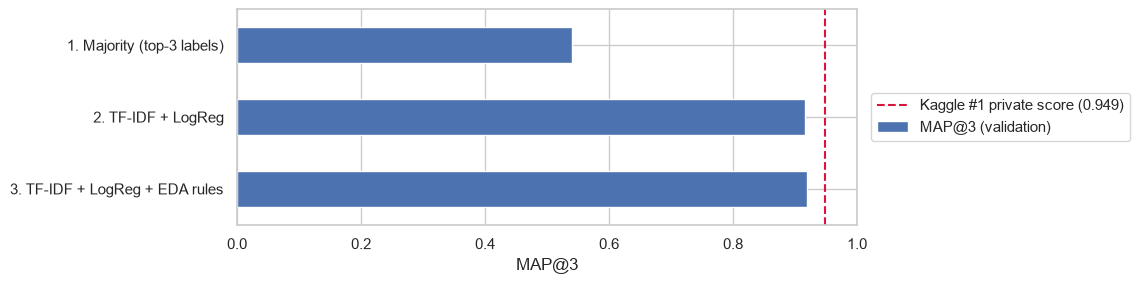

In [23]:
ax = results.plot.barh(color="#4C72B0", figsize=(8, 2.8))
ax.axvline(0.949, color="crimson", ls="--", label="Kaggle #1 private score (0.949)")
ax.set_xlim(0, 1)
ax.set_xlabel("MAP@3")
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

In [24]:
val = val.assign(pred=pred_rules)
val["hit@1"] = [p[0] == t for p, t in zip(val["pred"], val["target"])]
val["ap@3"] = [map_at_3([t], [p]) for p, t in zip(val["pred"], val["target"])]
val.groupby("Category")[["hit@1", "ap@3"]].mean().round(3).assign(rows=val["Category"].value_counts())

,hit@1,ap@3,rows
Category,,,
False_Correct,0.511,0.670,45
False_Misconception,0.841,0.913,1842
False_Neither,0.853,0.925,1286
True_Correct,0.928,0.964,2895
True_Misconception,0.388,0.579,80
True_Neither,0.681,0.840,1044


- The majority baseline reaches 0.540 because `True_Correct:NA`, `False_Neither:NA` and `True_Neither:NA` together cover 72.5 % of rows.
- TF-IDF + logistic regression reaches **0.917**.
- The two EDA rules (right/wrong answer, labels seen per question) add 0.003, to **0.920**. They cost nothing at prediction time, so we keep them.
- Per category, `True_Correct` scores 0.964 while `True_Misconception` (80 validation rows) scores 0.579 and `False_Correct` (45 rows) 0.670. The rare classes from Section 3.1 are where the model fails.

## 6. Kaggle submission

This is a **code competition**: Kaggle re-runs a notebook on the hidden test set (~16,000 rows), internet off, and reads its `submission.csv`. The competition is closed, but **late submissions are accepted** and receive a public and private score.

Below we train the final model on **all** training rows and write predictions for the local `test.csv` (3 rows) to check the file format.
For the real submission, the same pipeline is in [`kaggle_submit.py`](kaggle_submit.py). We pasted it into a Kaggle notebook with the competition data attached and submitted it as a late submission.

In [25]:
%%time
final_model = train_baseline(train["text"], train["target"])
labels_per_question_full = train.groupby("QuestionId")["target"].agg(set).to_dict()

test_p = preprocess(test, correct_answers)
test_proba = final_model.predict_proba(test_p["text"])
test_pred = top3_from_proba(test_proba, final_model.classes_,
                            allowed_mask(test_p, final_model.classes_, labels_per_question_full))
save_submission(test_p["row_id"], test_pred, "submission.csv")

CPU times: user 1min 21s, sys: 3.33 s, total: 1min 24s
Wall time: 1min 27s


,row_id,Category:Misconception
0,36696,True_Correct:NA True_Neither:NA True_Misconception:WNB
1,36697,False_Misconception:WNB False_Neither:NA False_Misconception:Incomplete
2,36698,True_Neither:NA True_Correct:NA True_Misconception:Shorter_is_bigger


**Late-submission score:** public = **0.90732** · private = **0.90760** (screenshot: [`submissions/assignment1_late_submission.png`](submissions/assignment1_late_submission.png))

The winning team's private score is **0.949**. Our private score of 0.908 is 0.042 below it. Our validation score (0.920) is 0.012 higher than the Kaggle score because it is computed on different rows.

## 7. Conclusion

**Key findings**

1. The target has 65 classes and is very imbalanced: 40 % `True_Correct`, about 73 % `NA` misconception, and a long tail of rare misconceptions.
2. The True/False half of the label follows from the chosen answer. We recover it from the training data with 99.95 % agreement.
3. Each question has only a handful of possible misconceptions, so the question strongly restricts the label space.
4. Explanations are short, noisy and often misspelled. A small number of identical texts carry conflicting labels, which sets a ceiling below 1.0.
5. A TF-IDF + logistic regression baseline with these rules reaches **MAP@3 ≈ 0.920** on validation, compared with 0.54 for the majority baseline.

**Next steps for Assignment 2**

- Fine-tune a pre-trained transformer (for example DeBERTa-v3) on the same `answer + correct + explanation` input and compare it with this baseline on the same split.
- Try class weights or oversampling for `True_Misconception`, `False_Correct` and the misconceptions with fewer than 25 rows.
- Switch to 5-fold cross-validation. One split gives one number, and the 0.003 gain from the rules is too small to trust from a single split.
- Keep the EDA rules as post-processing on top of any model.